# Proyecto ISHUME – Análisis de la tabla `modelos`
**PEA N.° 1:** operaciones con Pandas y NumPy  |  **PEA N.° 5:** gráficos con Matplotlib y Seaborn

Ejecuta las celdas en orden (Shift + Enter). Requiere el archivo `modelos.sql` en esta misma carpeta.

## 0. Librerías y funciones

In [1]:
import glob, re
import pandas as pd
import numpy as np

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

In [2]:
def titulo(t):
    print("\n" + "=" * 70 + f"\n{t}\n" + "=" * 70)

COLUMNAS = ["idModelo", "idCategoria", "idTipoMarco", "NombreMaterial", "Precio",
            "Cantidad", "TamanoHorizontal", "TamanoVertical", "Color",
            "NivelEducativo", "Imagen", "Estado"]

def leer_texto(ruta):
    for enc in ("utf-8-sig", "latin-1"):
        try:
            with open(ruta, encoding=enc) as f:
                return f.read()
        except UnicodeDecodeError:
            continue

def valor(v):
    v = v.strip()
    if v.upper() == "NULL": return None
    if v.lower() in ("true", "false"): return v.lower() == "true"
    try: return float(v)
    except ValueError: return v

def leer_inserts(texto):
    texto = re.sub(r"^\s*--.*$", "", texto, flags=re.M)      # quitar comentarios
    filas = []
    for m in re.finditer(r"INSERT\s+INTO\s+modelos\s+VALUES\s*\((.*?)\)\s*;", texto, re.I | re.S):
        vals = []
        for t in re.finditer(r"\s*(?:'((?:[^']|'')*)'|([^,]+?))\s*(?:,|$)", m.group(1)):
            vals.append(t.group(1).replace("''", "'") if t.group(1) is not None else valor(t.group(2)))
        if len(vals) == len(COLUMNAS):
            filas.append(vals)
    return pd.DataFrame(filas, columns=COLUMNAS)

## 1. Carga y exploración de datos

In [3]:
titulo("1. CARGA Y EXPLORACIÓN DE DATOS")
archivo = None
for f in glob.glob("*.sql"):
    if re.search(r"INSERT\s+INTO\s+modelos", leer_texto(f) or "", re.I):
        archivo = f
        break
if not archivo:
    raise FileNotFoundError("No encontré un .sql con INSERT INTO modelos en esta carpeta.")
print("Archivo leído:", archivo)

df = leer_inserts(leer_texto(archivo))
print("Modelos cargados (filas, columnas):", df.shape)
print("\nPrimeras filas:")
print(df.drop(columns="Imagen").head())
print("\nInformación de columnas:")
df.info()
print("\nResumen estadístico de las columnas numéricas:")
print(df.describe().round(2))
print("\nModelos por nivel educativo:")
print(df["NivelEducativo"].value_counts())


1. CARGA Y EXPLORACIÓN DE DATOS
Archivo leído: BD_ISHUME.sql
Modelos cargados (filas, columnas): (92, 12)

Primeras filas:
  idModelo idCategoria idTipoMarco     NombreMaterial  Precio  Cantidad  TamanoHorizontal  TamanoVertical   Color NivelEducativo  Estado
0  MOD-001     CAT-002     TIP-001          Unicornio   125.0       0.0              60.0            50.0  Rosado        Inicial    True
1  MOD-002     CAT-002     TIP-001        Mi Principe   125.0       0.0              60.0            50.0    Azul        Inicial    True
2  MOD-003     CAT-002     TIP-001  Mi Dulce Princesa   125.0       0.0              60.0            50.0  Rosado        Inicial    True
3  MOD-004     CAT-002     TIP-001        Mi Principe   125.0       0.0              60.0            50.0    Azul        Inicial    True
4  MOD-005     CAT-002     TIP-001          Unicornio   125.0       0.0              60.0            50.0  Rosado        Inicial    True

Información de columnas:
<class 'pandas.DataFrame'>
R

## 2. Limpieza de datos

In [4]:
titulo("2. LIMPIEZA DE DATOS")
print("Valores nulos por columna:")
print(df.isnull().sum())

# 2.1 Texto sin espacios sobrantes
for c in ["idModelo", "idCategoria", "idTipoMarco", "NombreMaterial", "Color", "NivelEducativo"]:
    df[c] = df[c].apply(lambda x: x.strip() if isinstance(x, str) else x)

# 2.2 Colores escritos de forma distinta ("Rosa" y "Rosado")
rosa = (df["Color"] == "Rosa").sum()
df["Color"] = df["Color"].replace({"Rosa": "Rosado"})
print(f"\nColores unificados ('Rosa' -> 'Rosado'): {rosa} registros")

# 2.3 Duplicados por código de modelo
antes = len(df)
df = df.drop_duplicates(subset="idModelo")
print(f"Códigos de modelo duplicados eliminados: {antes - len(df)}")

# 2.4 Medidas en 0.00 significan 'sin dato': se convierten en nulos y se rellenan
medidas = ["TamanoHorizontal", "TamanoVertical"]
ceros = int((df[medidas] == 0).any(axis=1).sum())
df[medidas] = df[medidas].replace(0, np.nan)
for c in medidas:
    df[c] = df[c].fillna(df.groupby("idTipoMarco")[c].transform("median"))  # mediana de su tipo de marco
    df[c] = df[c].fillna(df[c].median())                                     # si el tipo no tiene ninguna medida
print(f"Modelos con medidas en 0.00 corregidas con la mediana: {ceros}")
print("Nulos después de limpiar:", int(df[medidas].isnull().sum().sum()))


2. LIMPIEZA DE DATOS
Valores nulos por columna:
idModelo            0
idCategoria         0
idTipoMarco         0
NombreMaterial      0
Precio              0
Cantidad            0
TamanoHorizontal    0
TamanoVertical      0
Color               0
NivelEducativo      0
Imagen              0
Estado              0
dtype: int64

Colores unificados ('Rosa' -> 'Rosado'): 2 registros
Códigos de modelo duplicados eliminados: 0
Modelos con medidas en 0.00 corregidas con la mediana: 22
Nulos después de limpiar: 0


## 3. Filtrado

In [5]:
titulo("3. FILTRADO")
prom = df["Precio"].mean()
caros = df[df["Precio"] > prom]
print(f"Precio promedio: S/ {prom:.2f}")
print(f"Modelos con precio mayor al promedio: {len(caros)}")
print(caros[["idModelo", "NombreMaterial", "Precio", "NivelEducativo"]].head(10))

azules = df[(df["Color"] == "Azul") & (df["NivelEducativo"] == "Inicial")]
print(f"\nModelos de color Azul en nivel Inicial: {len(azules)}")
print(azules[["idModelo", "NombreMaterial", "Precio"]].head(10))


3. FILTRADO
Precio promedio: S/ 137.99
Modelos con precio mayor al promedio: 40
   idModelo      NombreMaterial  Precio NivelEducativo
34  MOD-035  Cuadro Marmol Blue   140.0        Inicial
35  MOD-036  Cuadro Marmol Pink   140.0        Inicial
36  MOD-037    Caballero Roblox   140.0        Inicial
37  MOD-038         Princesitas   140.0        Inicial
38  MOD-039     Guerreras K-pop   140.0        Inicial
39  MOD-040          Super Kids   140.0        Inicial
40  MOD-041      Cuadro Diagron   140.0        Inicial
41  MOD-042      Cuadro Diagron   140.0        Inicial
42  MOD-043     Dúo Mármol Blue   140.0        Inicial
43  MOD-044     Dúo Mármol Pink   140.0        Inicial

Modelos de color Azul en nivel Inicial: 24
   idModelo         NombreMaterial  Precio
1   MOD-002            Mi Principe   125.0
3   MOD-004            Mi Principe   125.0
5   MOD-006              Principes   125.0
7   MOD-008         Ultrabrillante   130.0
9   MOD-010     Pequeños Guerreros   130.0
11  MOD-012 

## 4. Agrupación y ordenamiento

In [6]:
titulo("4. AGRUPACIÓN Y ORDENAMIENTO")
por_nivel = df.groupby("NivelEducativo")["Precio"].agg(["count", "mean", "min", "max"]).round(2)
print("Precio por nivel educativo:")
print(por_nivel)

por_marco = df.groupby("idTipoMarco")["Precio"].agg(["count", "mean"]).round(2).sort_values("mean", ascending=False)
print("\nPrecio por tipo de marco (de mayor a menor promedio):")
print(por_marco)

por_cat = df.groupby("idCategoria")["Precio"].agg(["count", "mean", "sum"]).round(2)
print("\nPrecio por categoría:")
print(por_cat)

print("\nTop 5 colores más frecuentes:")
print(df["Color"].value_counts().head(5))

print("\nTop 5 modelos más caros:")
print(df.sort_values("Precio", ascending=False)[["idModelo", "NombreMaterial", "Precio"]].head(5))


4. AGRUPACIÓN Y ORDENAMIENTO
Precio por nivel educativo:
                       count    mean    min    max
NivelEducativo                                    
Inicial                   56  137.86  125.0  175.0
Primaria y Secundaria     36  138.19  125.0  175.0

Precio por tipo de marco (de mayor a menor promedio):
             count    mean
idTipoMarco               
TIP-007          9  165.00
TIP-008          3  153.33
TIP-009          7  147.14
TIP-006         20  139.75
TIP-005         15  135.67
TIP-004         26  130.00
TIP-003          3  128.33
TIP-001          8  125.00
TIP-002          1  125.00

Precio por categoría:
             count    mean     sum
idCategoria                       
CAT-001         19  156.58  2975.0
CAT-002         73  133.15  9720.0

Top 5 colores más frecuentes:
Color
Azul      27
Rosado    25
Negro     12
Blanco     8
Marrón     5
Name: count, dtype: int64

Top 5 modelos más caros:
   idModelo         NombreMaterial  Precio
49  MOD-050  Book Secret G

## 5. Operaciones con NumPy

In [7]:
titulo("5. OPERACIONES CON NUMPY")
p = df["Precio"].to_numpy()
print("Promedio del precio:      ", round(float(np.mean(p)), 2))
print("Mediana:                  ", round(float(np.median(p)), 2))
print("Desviación estándar:      ", round(float(np.std(p)), 2))
print("Mínimo / Máximo:          ", np.min(p), "/", np.max(p))
print("Percentil 25 / 75:        ", np.percentile(p, 25), "/", np.percentile(p, 75))

area = df["TamanoHorizontal"].to_numpy() * df["TamanoVertical"].to_numpy()
df["Area_cm2"] = np.round(area, 2)
df["Precio_por_cm2"] = np.round(p / area, 4)
print("\nÁrea promedio (cm2):      ", round(float(np.mean(area)), 2))
print("Correlación precio vs área:", round(float(np.corrcoef(p, area)[0, 1]), 3))

df["Gama"] = np.select([p <= np.percentile(p, 33), p <= np.percentile(p, 66)],
                       ["Económico", "Medio"], default="Premium")
print("\nClasificación por gama de precio (np.select):")
print(df["Gama"].value_counts())


5. OPERACIONES CON NUMPY
Promedio del precio:       137.99
Mediana:                   135.0
Desviación estándar:       11.68
Mínimo / Máximo:           125.0 / 175.0
Percentil 25 / 75:         130.0 / 140.0

Área promedio (cm2):       2707.91
Correlación precio vs área: -0.63

Clasificación por gama de precio (np.select):
Gama
Medio        39
Económico    38
Premium      15
Name: count, dtype: int64


## 6. Guardar resultado

In [8]:
df.to_csv("ishume_modelos_limpio.csv", index=False, encoding="utf-8-sig")
titulo("6. RESULTADO GUARDADO")
print("Archivo generado: ishume_modelos_limpio.csv  (", len(df), "modelos )")


6. RESULTADO GUARDADO
Archivo generado: ishume_modelos_limpio.csv  ( 92 modelos )


## 7. Gráficos con Matplotlib y Seaborn


7. GRÁFICOS CON MATPLOTLIB Y SEABORN


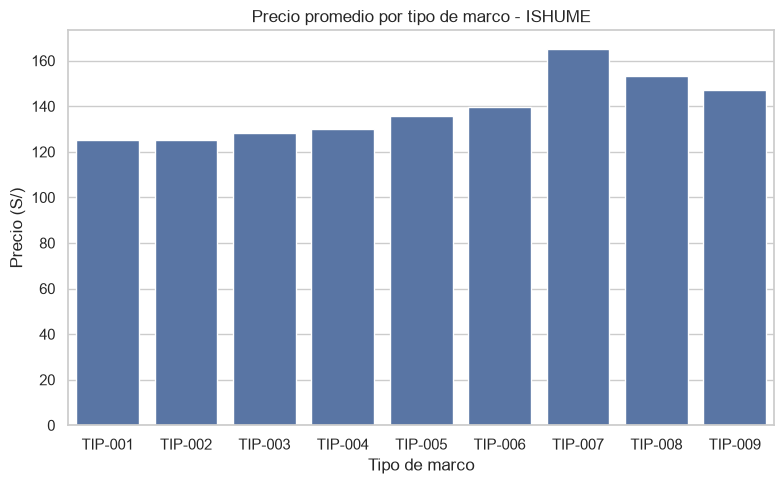

Guardado: grafico_precio_tipomarco.png


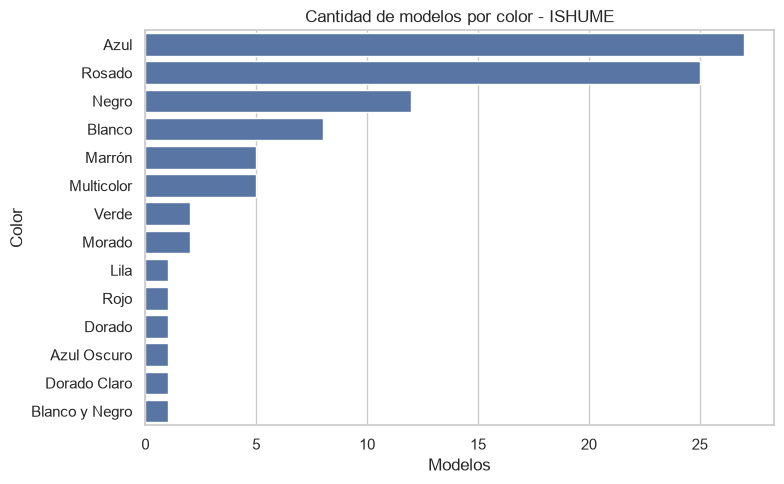

Guardado: grafico_colores.png


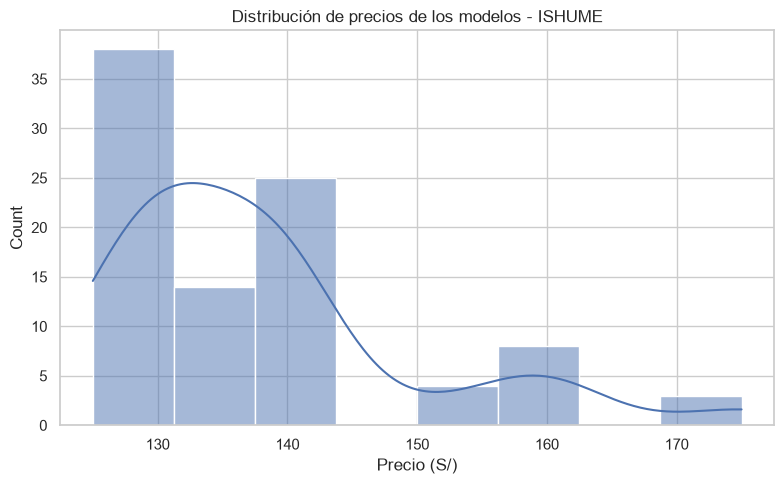

Guardado: grafico_distribucion_precios.png

ANÁLISIS COMPLETADO.


In [9]:
%matplotlib inline
titulo("7. GRÁFICOS CON MATPLOTLIB Y SEABORN")
try:
    import matplotlib
    import matplotlib.pyplot as plt
    import seaborn as sns
    sns.set_theme(style="whitegrid")

    plt.figure(figsize=(8, 5))
    sns.barplot(data=df, x="idTipoMarco", y="Precio", errorbar=None, order=sorted(df["idTipoMarco"].unique()))
    plt.title("Precio promedio por tipo de marco - ISHUME"); plt.xlabel("Tipo de marco"); plt.ylabel("Precio (S/)")
    plt.tight_layout(); plt.savefig("grafico_precio_tipomarco.png", dpi=120); plt.show()
    print("Guardado: grafico_precio_tipomarco.png")

    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, y="Color", order=df["Color"].value_counts().index)
    plt.title("Cantidad de modelos por color - ISHUME"); plt.xlabel("Modelos"); plt.ylabel("Color")
    plt.tight_layout(); plt.savefig("grafico_colores.png", dpi=120); plt.show()
    print("Guardado: grafico_colores.png")

    plt.figure(figsize=(8, 5))
    sns.histplot(df["Precio"], bins=8, kde=True)
    plt.title("Distribución de precios de los modelos - ISHUME"); plt.xlabel("Precio (S/)")
    plt.tight_layout(); plt.savefig("grafico_distribucion_precios.png", dpi=120); plt.show()
    print("Guardado: grafico_distribucion_precios.png")
except Exception as e:
    print("No se pudieron generar los gráficos:", e)

print("\nANÁLISIS COMPLETADO.")

In [11]:
## 8. Álgebra lineal: vectores y matrices

In [12]:
titulo("8. ÁLGEBRA LINEAL: VECTORES Y MATRICES")
precios = df["Precio"].to_numpy()
base = df["TamanoHorizontal"].to_numpy()
altura = df["TamanoVertical"].to_numpy()
print("Vector de precios (primeros 5):", precios[:5])
print("Dimensión del vector de precios:", precios.shape)

# Operaciones con vectores
perimetro = 2 * (base + altura)               # suma de vectores y producto por un escalar
print("\nPerímetro de los primeros 5 marcos (cm):", perimetro[:5])
print("Producto punto base . altura:", round(float(np.dot(base, altura)), 2))
print("Norma del vector de precios:", round(float(np.linalg.norm(precios)), 2))

# Matriz de medidas: una fila por modelo, columnas = base y altura
M = np.column_stack([base, altura])
print("\nMatriz de medidas M (modelos x medidas):", M.shape)
print(M[:5])
print("Transpuesta de M:", M.T.shape)
print("M por el vector [2, 2] (perímetro, multiplicación matricial), primeros 5:", (M @ np.array([2, 2]))[:5])

# Matrices de 2x2: M.T @ M, covarianza, determinante e inversa
G = M.T @ M
print("\nMatriz M.T @ M (2x2):")
print(np.round(G, 2))
C = np.cov(M.T)
print("\nMatriz de covarianza entre base y altura:")
print(np.round(C, 2))
print("Determinante de la covarianza:", round(float(np.linalg.det(C)), 2))
try:
    print("Matriz inversa de la covarianza:")
    print(np.round(np.linalg.inv(C), 4))
except np.linalg.LinAlgError:
    print("La matriz no tiene inversa (determinante 0).")

# Simulación de una compra con precios reales: total = cantidades . precios
codigos5 = df["idModelo"].to_numpy()[:5]
precios5 = precios[:5]
cantidades = np.array([10, 5, 8, 3, 12])
print("\nSimulación de una compra de 5 modelos:")
for cod, q, pr in zip(codigos5, cantidades, precios5):
    print(f"  {cod}: {q} unidades x S/ {pr:.2f} = S/ {q * pr:.2f}")
print("Total a pagar (producto punto cantidades . precios): S/", round(float(np.dot(cantidades, precios5)), 2))


8. ÁLGEBRA LINEAL: VECTORES Y MATRICES
Vector de precios (primeros 5): [125. 125. 125. 125. 125.]
Dimensión del vector de precios: (92,)

Perímetro de los primeros 5 marcos (cm): [220. 220. 220. 220. 220.]
Producto punto base . altura: 249127.63
Norma del vector de precios: 1328.28

Matriz de medidas M (modelos x medidas): (92, 2)
[[60. 50.]
 [60. 50.]
 [60. 50.]
 [60. 50.]
 [60. 50.]]
Transpuesta de M: (2, 92)
M por el vector [2, 2] (perímetro, multiplicación matricial), primeros 5: [220. 220. 220. 220. 220.]

Matriz M.T @ M (2x2):
[[320491.63 249127.63]
 [249127.63 194520.63]]

Matriz de covarianza entre base y altura:
[[239.81 169.37]
 [169.37 127.84]]
Determinante de la covarianza: 1971.5
Matriz inversa de la covarianza:
[[ 0.0648 -0.0859]
 [-0.0859  0.1216]]

Simulación de una compra de 5 modelos:
  MOD-001: 10 unidades x S/ 125.00 = S/ 1250.00
  MOD-002: 5 unidades x S/ 125.00 = S/ 625.00
  MOD-003: 8 unidades x S/ 125.00 = S/ 1000.00
  MOD-004: 3 unidades x S/ 125.00 = S/ 375.0

In [13]:
titulo("8. ÁLGEBRA LINEAL: VECTORES Y MATRICES")
precios = df["Precio"].to_numpy()
base = df["TamanoHorizontal"].to_numpy()
altura = df["TamanoVertical"].to_numpy()
print("Vector de precios (primeros 5):", precios[:5])
print("Dimensión del vector de precios:", precios.shape)

# Operaciones con vectores
perimetro = 2 * (base + altura)               # suma de vectores y producto por un escalar
print("\nPerímetro de los primeros 5 marcos (cm):", perimetro[:5])
print("Producto punto base . altura:", round(float(np.dot(base, altura)), 2))
print("Norma del vector de precios:", round(float(np.linalg.norm(precios)), 2))

# Matriz de medidas: una fila por modelo, columnas = base y altura
M = np.column_stack([base, altura])
print("\nMatriz de medidas M (modelos x medidas):", M.shape)
print(M[:5])
print("Transpuesta de M:", M.T.shape)
print("M por el vector [2, 2] (perímetro, multiplicación matricial), primeros 5:", (M @ np.array([2, 2]))[:5])

# Matrices de 2x2: M.T @ M, covarianza, determinante e inversa
G = M.T @ M
print("\nMatriz M.T @ M (2x2):")
print(np.round(G, 2))
C = np.cov(M.T)
print("\nMatriz de covarianza entre base y altura:")
print(np.round(C, 2))
print("Determinante de la covarianza:", round(float(np.linalg.det(C)), 2))
try:
    print("Matriz inversa de la covarianza:")
    print(np.round(np.linalg.inv(C), 4))
except np.linalg.LinAlgError:
    print("La matriz no tiene inversa (determinante 0).")

# Simulación de una compra con precios reales: total = cantidades . precios
codigos5 = df["idModelo"].to_numpy()[:5]
precios5 = precios[:5]
cantidades = np.array([10, 5, 8, 3, 12])
print("\nSimulación de una compra de 5 modelos:")
for cod, q, pr in zip(codigos5, cantidades, precios5):
    print(f"  {cod}: {q} unidades x S/ {pr:.2f} = S/ {q * pr:.2f}")
print("Total a pagar (producto punto cantidades . precios): S/", round(float(np.dot(cantidades, precios5)), 2))


8. ÁLGEBRA LINEAL: VECTORES Y MATRICES
Vector de precios (primeros 5): [125. 125. 125. 125. 125.]
Dimensión del vector de precios: (92,)

Perímetro de los primeros 5 marcos (cm): [220. 220. 220. 220. 220.]
Producto punto base . altura: 249127.63
Norma del vector de precios: 1328.28

Matriz de medidas M (modelos x medidas): (92, 2)
[[60. 50.]
 [60. 50.]
 [60. 50.]
 [60. 50.]
 [60. 50.]]
Transpuesta de M: (2, 92)
M por el vector [2, 2] (perímetro, multiplicación matricial), primeros 5: [220. 220. 220. 220. 220.]

Matriz M.T @ M (2x2):
[[320491.63 249127.63]
 [249127.63 194520.63]]

Matriz de covarianza entre base y altura:
[[239.81 169.37]
 [169.37 127.84]]
Determinante de la covarianza: 1971.5
Matriz inversa de la covarianza:
[[ 0.0648 -0.0859]
 [-0.0859  0.1216]]

Simulación de una compra de 5 modelos:
  MOD-001: 10 unidades x S/ 125.00 = S/ 1250.00
  MOD-002: 5 unidades x S/ 125.00 = S/ 625.00
  MOD-003: 8 unidades x S/ 125.00 = S/ 1000.00
  MOD-004: 3 unidades x S/ 125.00 = S/ 375.0

In [16]:
## 9. Principios y variables estadísticas

In [18]:
df = pd.read_csv("ishume_modelos_limpio.csv")
precio = df["Precio"].to_numpy()
area = df["TamanoHorizontal"].to_numpy() * df["TamanoVertical"].to_numpy()

print("PRINCIPIOS Y VARIABLES ESTADÍSTICAS - ISHUME")
print("=" * 55)
print("Variables numéricas:   Precio, Cantidad, TamanoHorizontal, TamanoVertical")
print("Variables categóricas: idCategoria, idTipoMarco, Color, NivelEducativo")

print("\n1) Tendencia central del precio")
print("   Promedio:", round(np.mean(precio), 2))
print("   Mediana: ", np.median(precio))

print("\n2) Posición y rango del precio")
print("   Mínimo:       ", np.min(precio))
print("   Máximo:       ", np.max(precio))
print("   Rango:        ", np.max(precio) - np.min(precio))
print("   Percentil 25: ", np.percentile(precio, 25))
print("   Percentil 75: ", np.percentile(precio, 75))

print("\n3) Frecuencias")
print(df["NivelEducativo"].value_counts())
print()
print(df["Color"].value_counts().head(5))

print("\n4) Relación entre variables")
print("   Correlación precio vs área:", round(np.corrcoef(precio, area)[0, 1], 3))

PRINCIPIOS Y VARIABLES ESTADÍSTICAS - ISHUME
Variables numéricas:   Precio, Cantidad, TamanoHorizontal, TamanoVertical
Variables categóricas: idCategoria, idTipoMarco, Color, NivelEducativo

1) Tendencia central del precio
   Promedio: 137.99
   Mediana:  135.0

2) Posición y rango del precio
   Mínimo:        125.0
   Máximo:        175.0
   Rango:         50.0
   Percentil 25:  130.0
   Percentil 75:  140.0

3) Frecuencias
NivelEducativo
Inicial                  56
Primaria y Secundaria    36
Name: count, dtype: int64

Color
Azul      27
Rosado    25
Negro     12
Blanco     8
Marrón     5
Name: count, dtype: int64

4) Relación entre variables
   Correlación precio vs área: -0.63


In [16]:
## 10. Varianza y desviación estándar

In [19]:
df = pd.read_csv("ishume_modelos_limpio.csv")
precio = df["Precio"].to_numpy()

print("VARIANZA Y DESVIACIÓN ESTÁNDAR DEL PRECIO - ISHUME")
print("=" * 55)
print("Desviación estándar:", round(np.std(precio), 2))
print("Varianza:           ", round(np.var(precio), 2))
print("Comprobación (desviación al cuadrado):", round(np.std(precio) ** 2, 2))

print("\nPor nivel educativo:")
for nivel, grupo in df.groupby("NivelEducativo"):
    p = grupo["Precio"].to_numpy()
    print(f"  {nivel}: desviación = {np.std(p):.2f} | varianza = {np.var(p):.2f}")

VARIANZA Y DESVIACIÓN ESTÁNDAR DEL PRECIO - ISHUME
Desviación estándar: 11.68
Varianza:            136.45
Comprobación (desviación al cuadrado): 136.45

Por nivel educativo:
  Inicial: desviación = 12.53 | varianza = 157.02
  Primaria y Secundaria: desviación = 10.22 | varianza = 104.38


In [16]:
## 11. Recursividad

In [17]:
titulo("9. RECURSIVIDAD")

def suma_recursiva(lista):
    """Suma los elementos de una lista llamándose a sí misma."""
    if len(lista) == 0:                            # caso base
        return 0
    return lista[0] + suma_recursiva(lista[1:])    # caso recursivo

def busqueda_binaria(codigos, objetivo, inicio, fin):
    """Busca un código en una lista ordenada, dividiendo el rango a la mitad en cada llamada."""
    if inicio > fin:                               # caso base: no se encontró
        return -1
    medio = (inicio + fin) // 2
    if codigos[medio] == objetivo:                 # caso base: encontrado
        return medio
    if objetivo < codigos[medio]:
        return busqueda_binaria(codigos, objetivo, inicio, medio - 1)
    return busqueda_binaria(codigos, objetivo, medio + 1, fin)

lista_precios = df["Precio"].tolist()
total_rec = suma_recursiva(lista_precios)
print("Suma recursiva de los precios de todos los modelos: S/", round(total_rec, 2))
print("Comprobación con sum() de Python:                   S/", round(sum(lista_precios), 2))
print("Los dos resultados coinciden:", abs(total_rec - sum(lista_precios)) < 1e-6)

codigos_ordenados = sorted(df["idModelo"].tolist())
for objetivo in ("MOD-045", "MOD-999"):
    pos = busqueda_binaria(codigos_ordenados, objetivo, 0, len(codigos_ordenados) - 1)
    if pos == -1:
        print(f"Búsqueda binaria recursiva: {objetivo} no existe en el catálogo")
    else:
        fila = df[df["idModelo"] == objetivo].iloc[0]
        print(f"Búsqueda binaria recursiva: {objetivo} encontrado en la posición {pos} -> {fila['NombreMaterial']}, S/ {fila['Precio']:.2f}")

print("\nANÁLISIS COMPLETADO.")



9. RECURSIVIDAD
Suma recursiva de los precios de todos los modelos: S/ 12695.0
Comprobación con sum() de Python:                   S/ 12695.0
Los dos resultados coinciden: True
Búsqueda binaria recursiva: MOD-045 encontrado en la posición 44 -> Cuadro Book, S/ 160.00
Búsqueda binaria recursiva: MOD-999 no existe en el catálogo

ANÁLISIS COMPLETADO.
